# Passaggio 6: simulazione della versione A con i costi (solo train)

**Obiettivo.** Rispondere alla domanda che decide il resto del progetto: i 7.4 punti base lordi per trade del Passaggio 4 sopravvivono ai costi di trading? Il motore è nel modulo [backtest.py](backtest.py); parte dai trade di `signals_15pairs_v2_train.csv` ([03_segnali.ipynb](03_segnali.ipynb)) e applica versione, costi e capitale.

**Da dove viene.** Il notebook è nato sulle prime 10 coppie: quella versione, con le conclusioni scritte dal gruppo, è in [Old files](../Old%20files/src/06_backtest/backtest_A.ipynb) e in `docs/Programma.md` (Passaggio 6). Qui lo stesso motore gira sulle 15 coppie; per queste il docente ha indicato di non considerare i costi, quindi lo scenario a costo 0 è il guadagno lordo e gli altri sono un'analisi di sensibilità.

**Regole fissate prima di guardare i risultati**
- importo fisso di 10.000 dollari per gamba, uguale sulle due gambe, senza leva; tutto chiuso a fine giornata;
- un trade ha 4 operazioni (apertura e chiusura di due gambe): costo del trade = 4 x costo per operazione;
- scenari di costo 0, 2, 5 e 10 punti base per operazione; **scenario realistico = 5** (decisione di Bea);
- capitale del portafoglio = 20.000 dollari per coppia (15 coppie = 300.000), i giorni senza trade valgono 0;
- Sharpe senza tasso privo di rischio, perché i trade durano ore e i dati sono 3 mesi;
- **il test (dal 17 settembre) non si legge**: il motore rifiuta trade dopo il 16 settembre.

Limite da ricordare: i risultati sono sul train, su cui sono stati scelti i parametri del segnale, quindi sono ottimistici.

## 1. Dati e controllo di coerenza

In [10]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # cartella del progetto: rende importabile src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.backtest import (load_trades, trading_days, apply_version, random_decisions, add_costs, daily_pnl, summary,
                      breakeven_cost, by_cost, by_group, entry_window, COST_SCENARIOS, MAIN_COST, OPERATIONS_PER_TRADE)

pd.options.display.float_format = "{:,.2f}".format
trades = load_trades()
days = trading_days()
print(len(trades), "trade,", len(days), "giorni di train,", trades.pair.nunique(), "coppie")

# A costo zero il motore deve riprodurre i numeri del Passaggio 4: 973 trade, 7.4 bps lordi
a0 = add_costs(apply_version(trades, "A"), 0)
assert len(a0) == 973 and round(a0.gross_bps.mean(), 1) == 7.4, "i numeri non tornano con il Passaggio 4"
assert np.allclose(a0.net_bps, a0.gross_bps)
print("controllo ok: 973 trade, guadagno lordo medio", round(a0.gross_bps.mean(), 2), "bps")

973 trade, 64 giorni di train, 15 coppie
controllo ok: 973 trade, guadagno lordo medio 7.44 bps


## 2. Versione A per scenario di costo

In [11]:
A = apply_version(trades, "A")
table = by_cost(A, days)
table[["trade", "gross_bps", "net_bps", "se_bps", "win_rate", "profit_factor", "pnl_usd", "total_return", "sharpe", "max_drawdown"]]

,trade,gross_bps,net_bps,se_bps,win_rate,profit_factor,pnl_usd,total_return,sharpe,max_drawdown
cost_bps_per_operation,,,,,,,,,,
0,973.00,7.44,7.44,2.03,0.60,1.45,"7,239.43",0.02,8.13,-0.00
2,973.00,7.44,-0.56,2.03,0.53,0.97,-544.57,-0.00,-0.62,-0.01
5,973.00,7.44,-12.56,2.03,0.39,0.52,"-12,220.57",-0.04,-13.55,-0.04
10,973.00,7.44,-32.56,2.03,0.20,0.20,"-31,680.57",-0.11,-31.28,-0.11


In [12]:
be = breakeven_cost(A)
print(f"Costo di pareggio: {be:.2f} bps per operazione ({OPERATIONS_PER_TRADE * be:.2f} bps per trade).")
print(f"Scenario realistico ({MAIN_COST} bps): costo {OPERATIONS_PER_TRADE * MAIN_COST} bps per trade contro {A.gross_bps.mean():.2f} bps lordi.")

Costo di pareggio: 1.86 bps per operazione (7.44 bps per trade).
Scenario realistico (5 bps): costo 20 bps per trade contro 7.44 bps lordi.


## 3. Da dove viene il guadagno (scenario realistico)

In [13]:
by_group(A, "pair")

,trade,gross_bps,net_bps,se_bps,win_rate
pair,,,,,
BAC-C,71,3.42,-16.58,6.17,0.42
CL-PG,63,6.61,-13.39,4.73,0.40
COP-EOG,61,-0.99,-20.99,5.33,0.34
CRM-WDAY,60,28.19,8.19,19.11,0.52
CSX-UNP,61,6.81,-13.19,4.16,0.38
DHR-TMO,62,6.59,-13.41,6.46,0.45
ELV-UNH,59,10.76,-9.24,7.36,0.44
GS-MS,72,9.62,-10.38,4.08,0.39
HD-LOW,65,4.39,-15.61,4.13,0.37


In [14]:
by_group(A, entry_window(A))

,trade,gross_bps,net_bps,se_bps,win_rate
finestra,,,,,
apertura (15-30 min),457,11.43,-8.57,3.16,0.46
dopo i 30 min,516,3.90,-16.10,2.60,0.34


In [15]:
by_group(A, "exit_reason")

,trade,gross_bps,net_bps,se_bps,win_rate
exit_reason,,,,,
fine_giornata,56,0.26,-19.74,18.24,0.09
rientro,464,38.79,18.79,1.39,0.71
stop,31,-32.10,-52.10,6.77,0.06
tempo,422,-23.17,-43.17,2.92,0.11


Il costo di pareggio per le sole entrate dopo i 30 minuti (le altre sono il rientro del gap della notte, vedi Passaggio 4):

In [16]:
w = entry_window(A)
for name, sub in A.groupby(w):
    print(f"{name}: {len(sub)} trade, lordo {sub.gross_bps.mean():.2f} bps, costo di pareggio {breakeven_cost(sub):.2f} bps per operazione")

apertura (15-30 min): 457 trade, lordo 11.43 bps, costo di pareggio 2.86 bps per operazione
dopo i 30 min: 516 trade, lordo 3.90 bps, costo di pareggio 0.98 bps per operazione


## 4. Curva di capitale (scenario realistico)

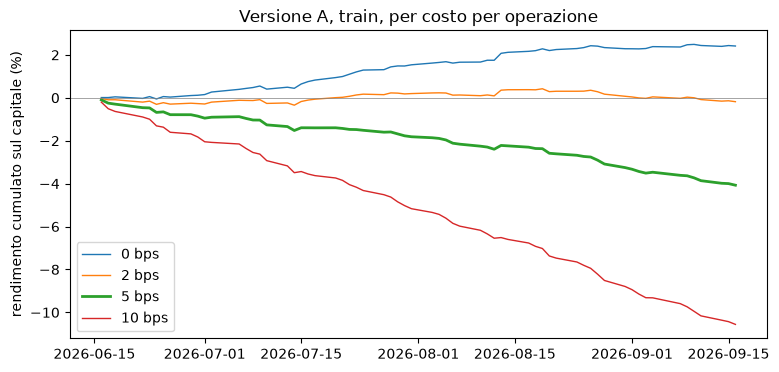

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
for c in COST_SCENARIOS:
    d = daily_pnl(add_costs(A, c), days)
    ax.plot(d.index, d.equity * 100, label=f"{c} bps", lw=2 if c == MAIN_COST else 1)
ax.axhline(0, color="grey", lw=0.5)
ax.set_ylabel("rendimento cumulato sul capitale (%)"); ax.set_title("Versione A, train, per costo per operazione"); ax.legend()
plt.show()

## 5. Prova del motore sulle versioni B e C (decisioni finte)

Serve solo a verificare che il motore funzioni quando arriveranno le decisioni dell'agente: blocco casuale del 20% dei segnali. **Non vanno interpretati**: non c'è nessun agente.

In [18]:
dec = random_decisions(trades, p_block=0.2, seed=0)
B = apply_version(trades, "B", dec)
print(len(B), "trade su", len(trades), "(bloccati", dec.decision.eq("blocca").sum(), ")")
print("B, finti, a", MAIN_COST, "bps:", round(add_costs(B, MAIN_COST).net_bps.mean(), 2), "bps netti")

# senza decisioni, B e C bloccano tutto? Qui il motore chiede le decisioni: la regola "ricerca fallita = blocca" è nel Passaggio 5
try:
    apply_version(trades, "B")
except ValueError as e:
    print("ok:", e)
try:
    apply_version(trades, "C", dec.assign(decision="segui"))
except NotImplementedError as e:
    print("ok:", e)

785 trade su 973 (bloccati 188 )
B, finti, a 5 bps: -11.01 bps netti
ok: la versione B richiede le decisioni dell'agente
ok: versione C: serve la simulazione con direzione scelta dall'agente


## 6. Cosa ci dicono i risultati

Da scrivere dal gruppo sui numeri delle tabelle qui sopra, che sono quelli delle 15 coppie. La lettura fatta sulle prime 10 coppie (624 trade) è in [Old files](../Old%20files/src/06_backtest/backtest_A.ipynb) e in `docs/Programma.md`, Passaggio 6: vale per quelle coppie, non per queste.

**Limiti.** Costi per operazione stimati, non misurati; nessun costo di prestito dei titoli; una parte dei trade è eseguita a un prezzo vecchio (barra riempita); risultati sul train, quindi ottimistici; la versione B aspetta le decisioni dell'agente (`python -m src.agent`) e la versione C non è simulata (decisioni finte nella sezione 5, non interpretabili).